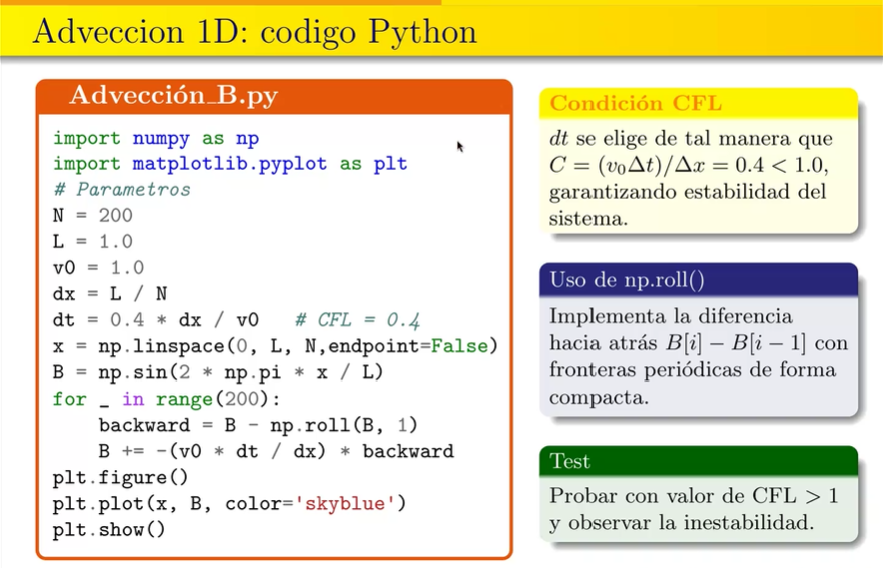

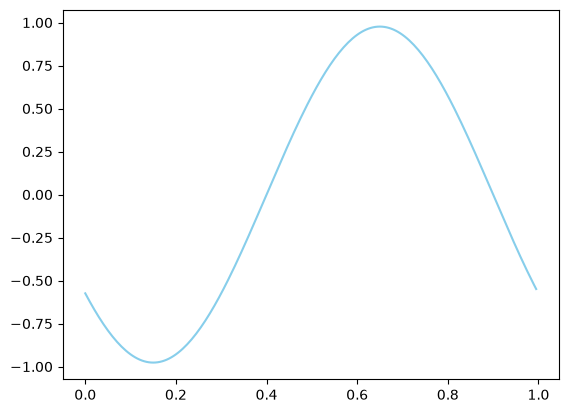

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# Parametros
N = 200
L = 1.0
v0 = 1.0
dx = L / N
dt = 0.4 * dx / v0  # CFL = 0.4
x = np.linspace(0, L, N, endpoint=False)
B = np.sin(2 * np.pi * x / L)

for _ in range(200):
    backward = B - np.roll(B, 1)
    B += -(v0 * dt / dx) * backward

plt.figure()
plt.plot(x, B, color='skyblue')
plt.show()

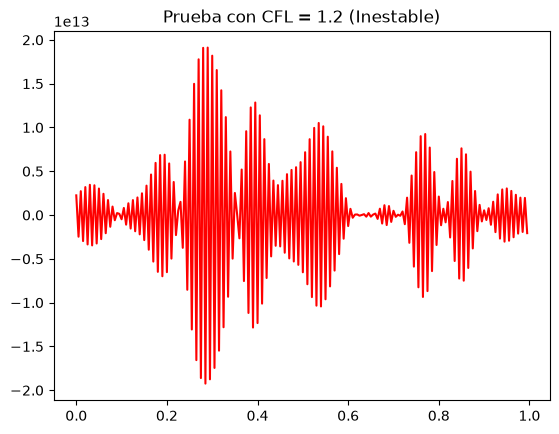

In [14]:
# Parametros con CFL > 1 
dx = L / N
dt = 1.2 * dx / v0  # CFL = 1.2 
x = np.linspace(0, L, N, endpoint=False)
B = np.sin(2 * np.pi * x / L)

for _ in range(200):
    backward = B - np.roll(B, 1)
    B += -(v0 * dt / dx) * backward

plt.figure()
plt.plot(x, B, color='red')
plt.title("Prueba con CFL = 1.2 (Inestable)")
plt.show()

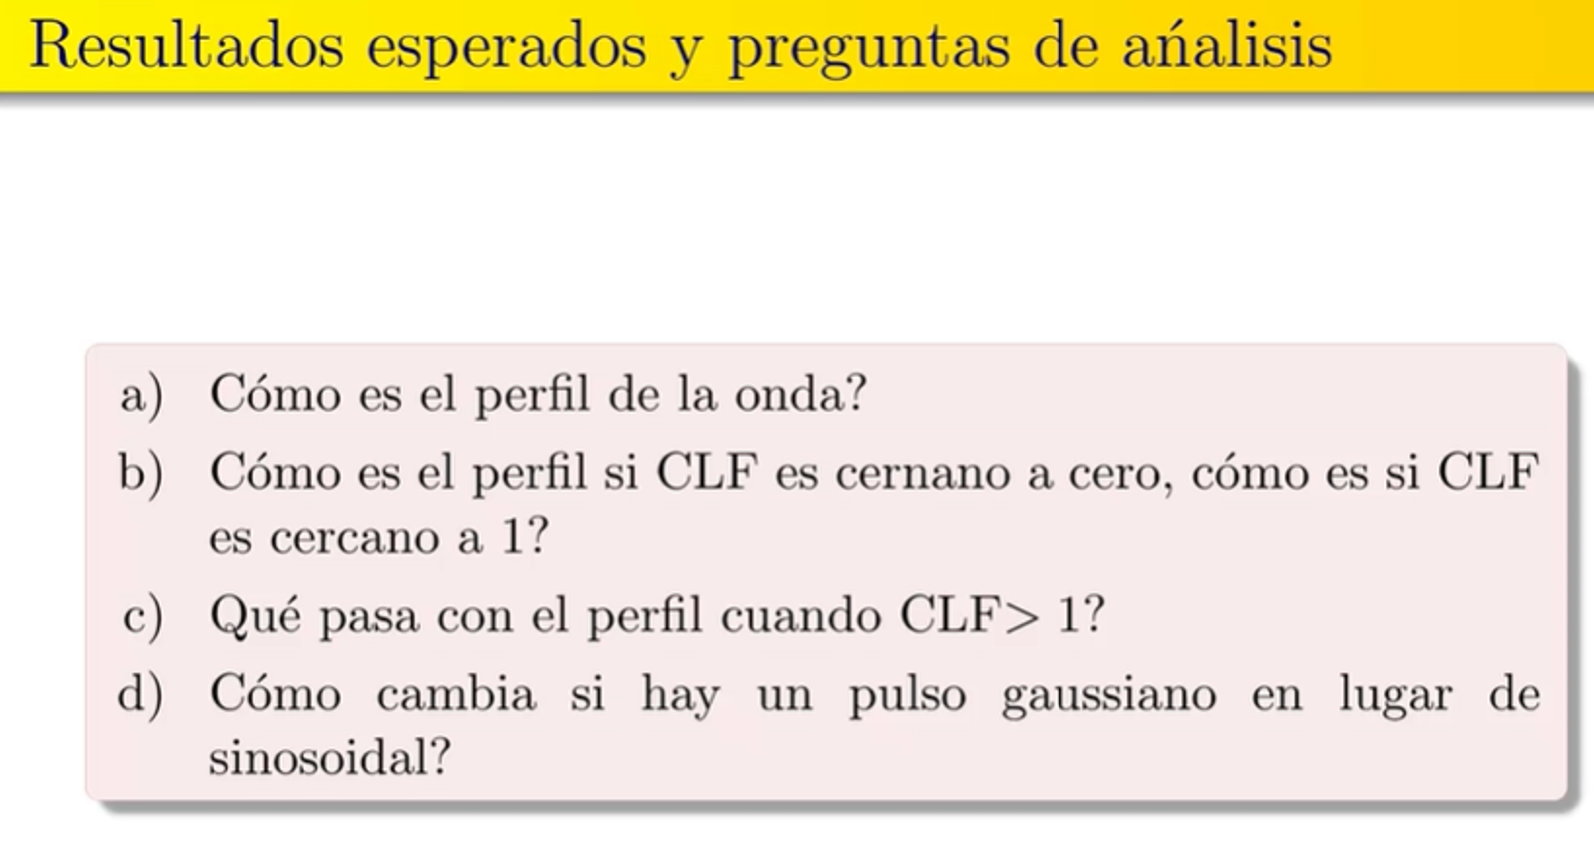

# Problema 1: Advección 1D de campo magnético

## I. Configuración del problema

$$\frac{\partial B}{\partial t} + v_0 \frac{\partial B}{\partial x} = 0$$

Condición inicial: $B(x, 0) = \sin(2\pi x / L)$. Fronteras periódicas y velocidad de advección $v_0$ constante.

## II. Esquema upwind explícito

$$B_i^{n+1} = B_i^n - \left(\frac{v_0 \Delta t}{\Delta x}\right)\left(B_i^n - B_{i-1}^n\right)$$

La condición CFL es $C = \dfrac{v_0 \Delta t}{\Delta x} \leq 1$. Si $C > 1$, aparece inestabilidad numérica.

## Qué observamos y qué aprendemos

- **Perfil que viaja:** $B$ se desplaza a velocidad $v_0$ sin cambiar demasiado su forma.
- **Difusión numérica:** el esquema upwind introduce amortiguamiento artificial.
- **Inestabilidad CFL:** si $C > 1$ la solución explota por inestabilidad numérica.
- **Conexión física:** es una demostración mínima y simple del *flux freezing* en 1D.

## Pregunta a) Perfil de la onda sinusoidal (CFL = 0.4)

Se usa el mismo tiempo final en todos los experimentos: `t_final = 0.4`, es decir, la onda recorre 0.4 L.

In [26]:
# Parámetro numérico
CFL = 0.4
dt = CFL * dx / v0

# Tiempo final y número de pasos
t_final = 0.4
nt = int(t_final / dt)
t = nt * dt

# Condición inicial sinusoidal
B = np.sin(2 * np.pi * x / L)
B_inicial = B.copy()

print("dx =", dx)
print("dt =", dt)
print("nt =", nt)
print("t  =", t)

dx = 0.005
dt = 0.002
nt = 200
t  = 0.4


Amplitud máxima = 0.9765904472536565
Error máximo    = 0.023409552746343487


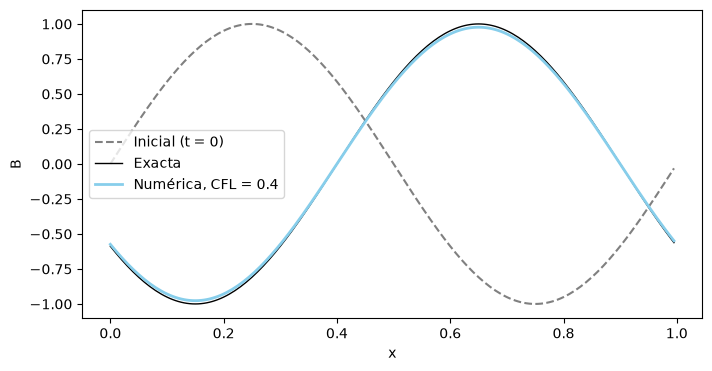

In [27]:
# Evolución temporal
for n in range(nt):
    B_nuevo = np.zeros(N)
    for i in range(N):
        backward = B[i] - B[i - 1]
        B_nuevo[i] = B[i] - (v0 * dt / dx) * backward
    B = B_nuevo

# Solución exacta: perfil inicial desplazado v0*t
B_exacta = np.sin(2 * np.pi * (x - v0 * t) / L)

# Medidas
amplitud = np.max(B)
error_max = np.max(np.abs(B - B_exacta))
print("Amplitud máxima =", amplitud)
print("Error máximo    =", error_max)

# Gráfica
plt.figure(figsize=(8, 4))
plt.plot(x, B_inicial, '--', color='gray', label='Inicial (t = 0)')
plt.plot(x, B_exacta, color='black', linewidth=1, label='Exacta')
plt.plot(x, B, color='skyblue', linewidth=2, label='Numérica, CFL = 0.4')
plt.xlabel('x')
plt.ylabel('B')
plt.legend()
plt.show()

### Respuesta a)

El perfil sigue siendo una **onda suave en forma de seno**, pero se **movió hacia la derecha**. Avanzó 0.4 L (la velocidad $v_0$ por el tiempo $t$): el pico que estaba en $x = 0.25$ ahora está en $x = 0.65$. Esto es justo lo que dice la ecuación de advección: la onda viaja sin cambiar de forma.

Sin embargo, el método no es perfecto: la altura de la onda bajó un poco, de 1.000 a **0.977**.

## Pregunta b) CFL cercano a cero y CFL cercano a 1

Se repite el cálculo completo con tres valores de CFL, siempre hasta `t_final = 0.4`. Primero **CFL = 0.1**.

In [28]:
# CFL cercano a cero
CFL = 0.1
dt = CFL * dx / v0
nt = int(t_final / dt)
t = nt * dt

B = np.sin(2 * np.pi * x / L)

for n in range(nt):
    B_nuevo = np.zeros(N)
    for i in range(N):
        backward = B[i] - B[i - 1]
        B_nuevo[i] = B[i] - (v0 * dt / dx) * backward
    B = B_nuevo

B_cfl_01 = B.copy()
B_exacta = np.sin(2 * np.pi * (x - v0 * t) / L)

print("CFL =", CFL, " pasos =", nt)
print("Amplitud máxima =", np.max(B_cfl_01))
print("Error máximo    =", np.max(np.abs(B_cfl_01 - B_exacta)))

CFL = 0.1  pasos = 800
Amplitud máxima = 0.9650944798748369
Error máximo    = 0.034905520125163125


Ahora **CFL = 0.9** (cercano a 1).

In [18]:
# CFL cercano a 1
CFL = 0.9
dt = CFL * dx / v0
nt = int(round(t_final / dt))
t = nt * dt

B = np.sin(2 * np.pi * x / L)

for n in range(nt):
    backward = B - np.roll(B, 1)
    B += -(v0 * dt / dx) * backward

B_cfl_09 = B.copy()
B_exacta = np.sin(2 * np.pi * (x - v0 * t) / L)

print("CFL =", CFL, " pasos =", nt)
print("Amplitud máxima =", np.max(B_cfl_09))
print("Error máximo    =", np.max(np.abs(B_cfl_09 - B_exacta)))

CFL = 0.9  pasos = 89
Amplitud máxima = 0.9960501548404861
Error máximo    = 0.003944910361372123


Por último **CFL = 1.0** (caso límite).

In [29]:
# CFL cercano a 1
CFL = 0.9
dt = CFL * dx / v0
nt = int(t_final / dt)
t = nt * dt

B = np.sin(2 * np.pi * x / L)

for n in range(nt):
    B_nuevo = np.zeros(N)
    for i in range(N):
        backward = B[i] - B[i - 1]
        B_nuevo[i] = B[i] - (v0 * dt / dx) * backward
    B = B_nuevo

B_cfl_09 = B.copy()
B_exacta = np.sin(2 * np.pi * (x - v0 * t) / L)

print("CFL =", CFL, " pasos =", nt)
print("Amplitud máxima =", np.max(B_cfl_09))
print("Error máximo    =", np.max(np.abs(B_cfl_09 - B_exacta)))

CFL = 0.9  pasos = 88
Amplitud máxima = 0.9960795440580115
Error máximo    = 0.0039007167981256474


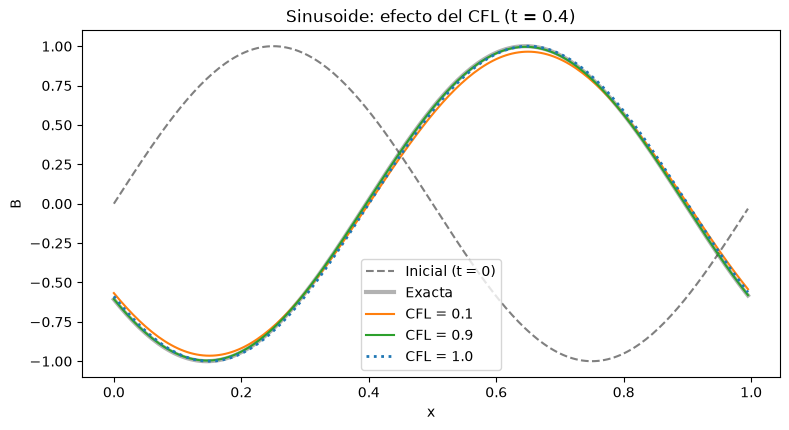

In [30]:
# Comparación de los tres casos
plt.figure(figsize=(9, 4.5))
plt.plot(x, B_inicial, '--', color='gray', label='Inicial (t = 0)')
plt.plot(x, B_exacta, color='black', linewidth=3, alpha=0.3, label='Exacta')
plt.plot(x, B_cfl_01, color='tab:orange', label='CFL = 0.1')
plt.plot(x, B_cfl_09, color='tab:green', label='CFL = 0.9')
plt.plot(x, B_cfl_10, color='tab:blue', linestyle=':', linewidth=2, label='CFL = 1.0')
plt.xlabel('x')
plt.ylabel('B')
plt.title('Sinusoide: efecto del CFL (t = 0.4)')
plt.legend()
plt.show()

### Respuesta b)

| CFL | Pasos | Altura de la onda (inicial = 1) |
|---|---|---|
| 0.1 | 800 | 0.965 |
| 0.4 | 200 | 0.977 |
| 0.9 | 88 | 0.996 |
| 1.0 | 80 | 1.000 |

- **CFL cercano a 0 (0.1):** la onda es estable y viaja a la velocidad correcta, pero llega **más aplastada** (altura 0.965). Con pasos de tiempo tan pequeños se necesitan muchos pasos (800).
- **CFL cercano a 1 (0.9):** la onda casi no pierde altura (0.996). Cuando **CFL = 1**, la fórmula se reduce a $B_i^{n+1} = B_{i-1}^n$: en cada paso cada valor simplemente se corre una celda hacia la derecha. La onda llega **idéntica** a la solución exacta.

**En resumen:** cuanto más cerca de 1 esté el CFL (sin pasarse), mejor es el resultado.


## Pregunta c) CFL > 1

Se usa CFL = 1.2, con 200 pasos. En cada paso se guarda la amplitud máxima `max|B|` para ver cómo evoluciona.

In [32]:
# CFL mayor que 1
CFL = 1.2
dt = CFL * dx / v0
nt = 200

B = np.sin(2 * np.pi * x / L)

# Registro de la amplitud en cada paso
amp = np.zeros(nt)

for n in range(nt):
    B_nuevo = np.zeros(N)
    for i in range(N):
        backward = B[i] - B[i - 1]
        B_nuevo[i] = B[i] - (v0 * dt / dx) * backward
    B = B_nuevo
    amp[n] = np.max(np.abs(B))
    if n == 99:
        B_paso_100 = B.copy()
    if n == 119:
        B_paso_120 = B.copy()

print("Amplitud en el paso  50:", amp[49])
print("Amplitud en el paso 100:", amp[99])
print("Amplitud en el paso 120:", amp[119])
print("Amplitud en el paso 150:", amp[149])
print("Amplitud en el paso 200:", amp[199])

Amplitud en el paso  50: 1.0059381312937392
Amplitud en el paso 100: 1.063050558766721
Amplitud en el paso 120: 42.89732473590103
Amplitud en el paso 150: 989991.5727593297
Amplitud en el paso 200: 19241610958283.953


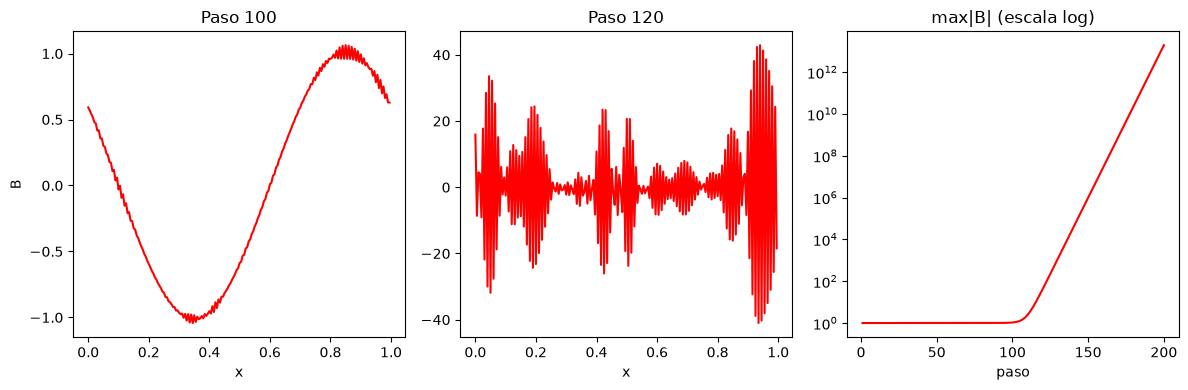

In [33]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.plot(x, B_paso_100, color='red')
plt.title('Paso 100')
plt.xlabel('x')
plt.ylabel('B')

plt.subplot(1, 3, 2)
plt.plot(x, B_paso_120, color='red')
plt.title('Paso 120')
plt.xlabel('x')

plt.subplot(1, 3, 3)
plt.semilogy(np.arange(1, nt + 1), amp, color='red')
plt.title('max|B| (escala log)')
plt.xlabel('paso')

plt.tight_layout()
plt.show()

### Respuesta c)

Cuando CFL > 1 la solución diverge.

Al principio la onda se ve normal (hasta el paso ~80 su amplitud sigue en ≈ 1.01). Pero debido a errores de redondeo, el método los amplifica en cada paso hasta que dominan la solución:

- paso 100: amplitud ≈ 1.06 (aparece ruido numérico)
- paso 120: amplitud ≈ 43
- paso 150: amplitud ≈ 10⁶
- paso 200: amplitud ≈ 2 × 10¹³

El perfil deja de ser una onda y queda dominado por oscilaciones de una celda a otra que crecen en cada paso. 

**Causa:** con CFL > 1 la onda avanza más de una celda por paso, pero el esquema solo usa la celda vecina $i-1$. Le falta información y no puede representar el movimiento. Por eso se debe cumplir la condición CFL ≤ 1.

## Pregunta d) Pulso gaussiano en lugar de sinusoidal

Se cambia solo la condición inicial: un pulso centrado en `x0 = 0.3` con ancho `sigma = 0.05`. Se repiten los casos CFL = 0.1, 0.9, 1.0 y 1.2.

Altura inicial del pulso = 1.0
CFL = 0.1  altura = 0.7624960014809076  posición del pico = 0.7000000000000001
CFL = 0.9  altura = 0.9624075770821029  posición del pico = 0.6950000000000001
CFL = 1.0  altura = 1.0  posición del pico = 0.7000000000000001


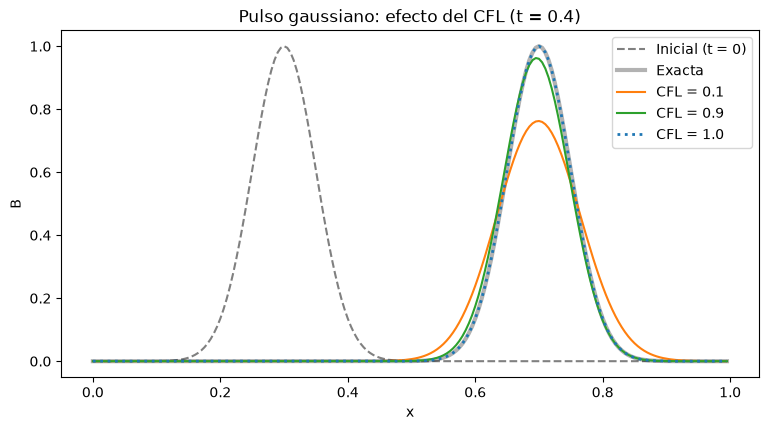

In [34]:
# Parámetros del pulso gaussiano
x0 = 0.3
sigma = 0.05

# Condición inicial
B_gauss_inicial = np.exp(-(x - x0) ** 2 / (2 * sigma ** 2))

# CFL = 0.1
CFL = 0.1
dt = CFL * dx / v0
nt = int(t_final / dt)
t = nt * dt
B = B_gauss_inicial.copy()
for n in range(nt):
    B_nuevo = np.zeros(N)
    for i in range(N):
        backward = B[i] - B[i - 1]
        B_nuevo[i] = B[i] - (v0 * dt / dx) * backward
    B = B_nuevo
B_g_01 = B.copy()

# CFL = 0.9
CFL = 0.9
dt = CFL * dx / v0
nt = int(t_final / dt)
t = nt * dt
B = B_gauss_inicial.copy()
for n in range(nt):
    B_nuevo = np.zeros(N)
    for i in range(N):
        backward = B[i] - B[i - 1]
        B_nuevo[i] = B[i] - (v0 * dt / dx) * backward
    B = B_nuevo
B_g_09 = B.copy()

# CFL = 1.0
CFL = 1.0
dt = CFL * dx / v0
nt = int(t_final / dt)
t = nt * dt
B = B_gauss_inicial.copy()
for n in range(nt):
    B_nuevo = np.zeros(N)
    for i in range(N):
        backward = B[i] - B[i - 1]
        B_nuevo[i] = B[i] - (v0 * dt / dx) * backward
    B = B_nuevo
B_g_10 = B.copy()

# Solución exacta: el pulso se mueve de x0 a x0 + v0*t
B_g_exacta = np.exp(-(x - (x0 + v0 * t)) ** 2 / (2 * sigma ** 2))

print("Altura inicial del pulso =", np.max(B_gauss_inicial))
print("CFL = 0.1  altura =", np.max(B_g_01), " posición del pico =", x[np.argmax(B_g_01)])
print("CFL = 0.9  altura =", np.max(B_g_09), " posición del pico =", x[np.argmax(B_g_09)])
print("CFL = 1.0  altura =", np.max(B_g_10), " posición del pico =", x[np.argmax(B_g_10)])

plt.figure(figsize=(9, 4.5))
plt.plot(x, B_gauss_inicial, '--', color='gray', label='Inicial (t = 0)')
plt.plot(x, B_g_exacta, color='black', linewidth=3, alpha=0.3, label='Exacta')
plt.plot(x, B_g_01, color='tab:orange', label='CFL = 0.1')
plt.plot(x, B_g_09, color='tab:green', label='CFL = 0.9')
plt.plot(x, B_g_10, color='tab:blue', linestyle=':', linewidth=2, label='CFL = 1.0')
plt.xlabel('x')
plt.ylabel('B')
plt.title('Pulso gaussiano: efecto del CFL (t = 0.4)')
plt.legend()
plt.show()

Ahora el pulso gaussiano con **CFL = 1.2** (inestable), 200 pasos.

Amplitud en el paso  50: 1.0654185556623896
Amplitud en el paso  80: 339.0161581639757
Amplitud en el paso 100: 252314.64068957177
Amplitud en el paso 200: 7.335652350995204e+19


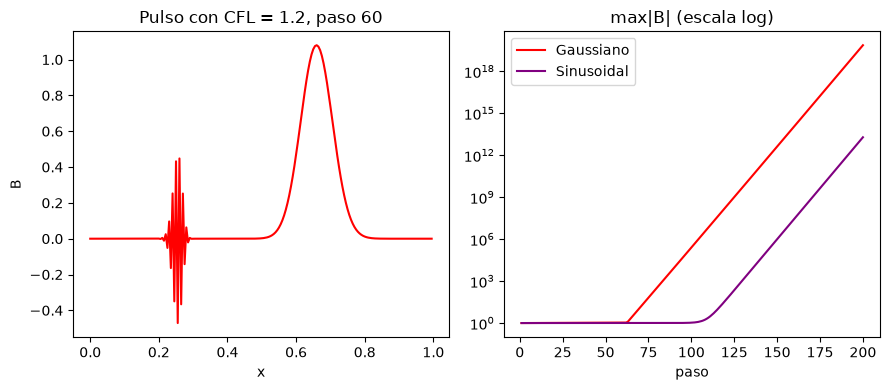

In [35]:
# Pulso gaussiano con CFL mayor que 1
CFL = 1.2
dt = CFL * dx / v0
nt = 200

B = B_gauss_inicial.copy()
amp_g = np.zeros(nt)

for n in range(nt):
    B_nuevo = np.zeros(N)
    for i in range(N):
        backward = B[i] - B[i - 1]
        B_nuevo[i] = B[i] - (v0 * dt / dx) * backward
    B = B_nuevo
    amp_g[n] = np.max(np.abs(B))
    if n == 59:
        B_g_paso_60 = B.copy()

print("Amplitud en el paso  50:", amp_g[49])
print("Amplitud en el paso  80:", amp_g[79])
print("Amplitud en el paso 100:", amp_g[99])
print("Amplitud en el paso 200:", amp_g[199])

plt.figure(figsize=(9, 4))

plt.subplot(1, 2, 1)
plt.plot(x, B_g_paso_60, color='red')
plt.title('Pulso con CFL = 1.2, paso 60')
plt.xlabel('x')
plt.ylabel('B')

plt.subplot(1, 2, 2)
plt.semilogy(np.arange(1, nt + 1), amp_g, color='red', label='Gaussiano')
plt.semilogy(np.arange(1, nt + 1), amp, color='purple', label='Sinusoidal')
plt.title('max|B| (escala log)')
plt.xlabel('paso')
plt.legend()

plt.tight_layout()
plt.show()

### Respuesta d)

| CFL | Altura del pulso (inicial = 1) | Error máximo vs. exacta |
|---|---|---|
| 0.1 | 0.763 | 2.4 × 10⁻¹ |
| 0.4 | 0.822 | 1.8 × 10⁻¹ |
| 0.9 | 0.962 | 3.8 × 10⁻² |
| 1.0 | 1.000 | ~10⁻⁸ |

- **Mismo desplazamiento:** el pico pasa de $x = 0.3$ a $x = 0.7$ ($v_0 t = 0.4$), igual que la sinusoide.
- **Más difusión que la sinusoide:** el pulso es angosto, y un pulso angosto contiene longitudes de onda cortas, que el upwind amortigua más. Con CFL = 0.1 la altura cae a **0.76** (la sinusoide solo caía a 0.965) y el pulso se **ensancha y se aplana**, ya que la difusión conserva el área pero la redistribuye.
- **CFL = 1:** el pulso viaja casi intacto, sin deformarse.
- **CFL > 1:** la inestabilidad aparece **mucho antes** que con la sinusoide: la amplitud ya es 339 en el paso 80 (la sinusoide seguía en ≈ 1.01) y llega a ≈ 7 × 10¹⁹ en el paso 200. El pulso tiene componentes de alta frecuencia desde el inicio, justo las que el esquema amplifica cuando CFL > 1, mientras que la sinusoide solo las genera por el ruido de redondeo.